In [1]:
# AirAware: Air Pollution Early Warning System

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout

print("AirAware environment is ready!")
print("TensorFlow version:", tf.__version__)

AirAware environment is ready!
TensorFlow version: 2.21.0


In [2]:
import pandas as pd

df = pd.read_csv("/content/city_day.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (29531, 16)

Columns:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
# Dataset overview
print("Dataset shape:", df.shape)

print("\nColumn data types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nMissing values:")
missing = df.isnull().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame(name="Missing Count"))

print("\nDate range:")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print(df["Date"].min(), "to", df["Date"].max())

print("\nNumber of cities:", df["City"].nunique())
print("Available cities:")
print(sorted(df["City"].dropna().unique()))

Dataset shape: (29531, 16)

Column data types:


,Data Type
City,object
Date,object
PM2.5,float64
PM10,float64
NO,float64
NO2,float64
NOx,float64
NH3,float64
CO,float64
SO2,float64



Missing values:


,Missing Count
Xylene,18109
PM10,11140
NH3,10328
Toluene,8041
Benzene,5623
AQI,4681
AQI_Bucket,4681
PM2.5,4598
NOx,4185
O3,4022



Date range:
2015-01-01 00:00:00 to 2020-07-01 00:00:00

Number of cities: 26
Available cities:
['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Ernakulam', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']


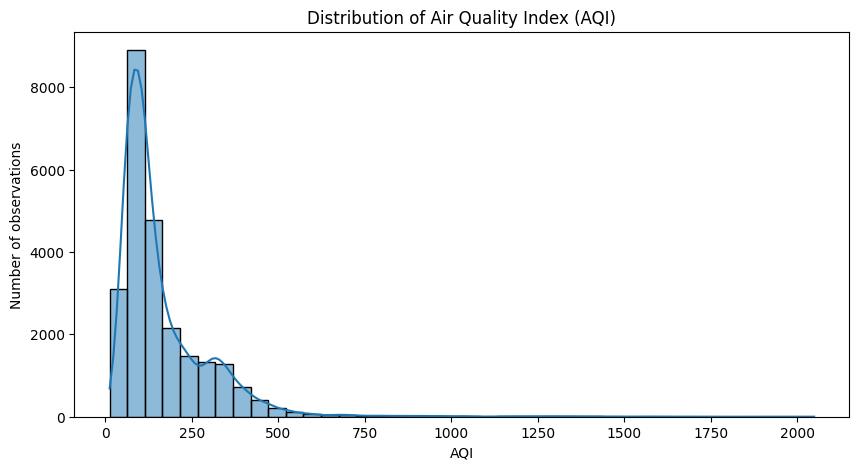

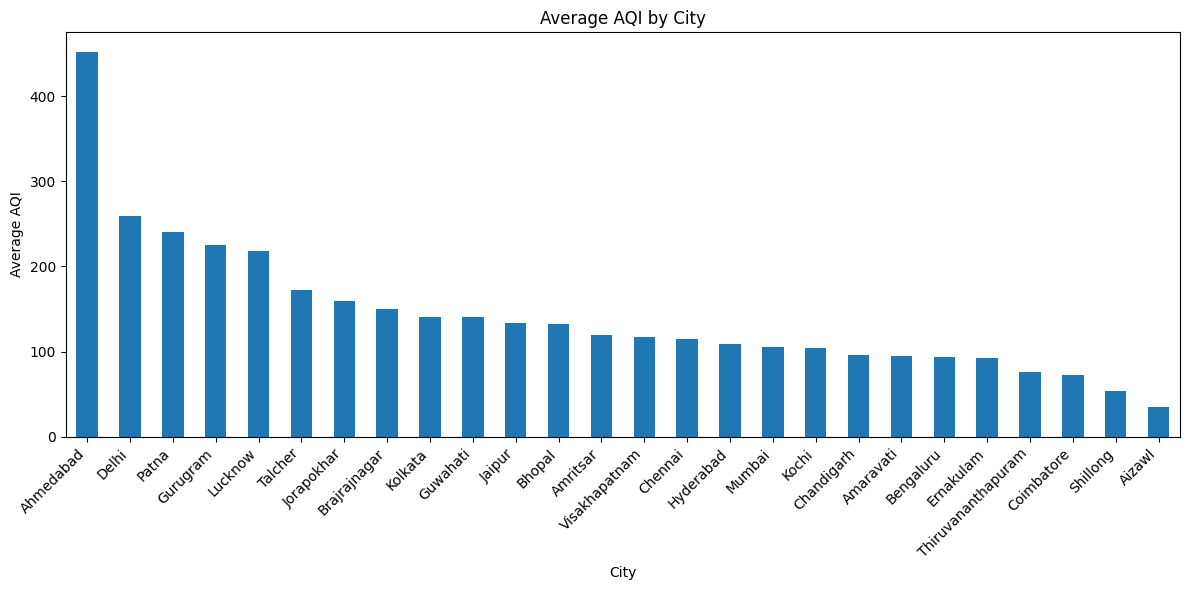

In [4]:
# AQI distribution
plt.figure(figsize=(10, 5))
sns.histplot(df["AQI"].dropna(), bins=40, kde=True)
plt.title("Distribution of Air Quality Index (AQI)")
plt.xlabel("AQI")
plt.ylabel("Number of observations")
plt.show()

# Average AQI by city
city_aqi = (
    df.groupby("City")["AQI"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
city_aqi.plot(kind="bar")
plt.title("Average AQI by City")
plt.xlabel("City")
plt.ylabel("Average AQI")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [5]:
# Check how much AQI data each city has
city_summary = (
    df.groupby("City")
      .agg(
          Total_Days=("Date", "count"),
          Available_AQI=("AQI", "count"),
          Average_AQI=("AQI", "mean")
      )
      .sort_values("Available_AQI", ascending=False)
)

display(city_summary)

,Total_Days,Available_AQI,Average_AQI
City,,,
Delhi,2009,1999,259.487744
Bengaluru,2009,1910,94.318325
Lucknow,2009,1893,217.973059
Chennai,2009,1884,114.502654
Hyderabad,2006,1880,109.207447
Patna,1858,1459,240.782042
Gurugram,1679,1453,225.123882
Ahmedabad,2009,1334,452.122939
Visakhapatnam,1462,1171,117.269855


Selected city: Delhi
Available AQI records: 1999
Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00


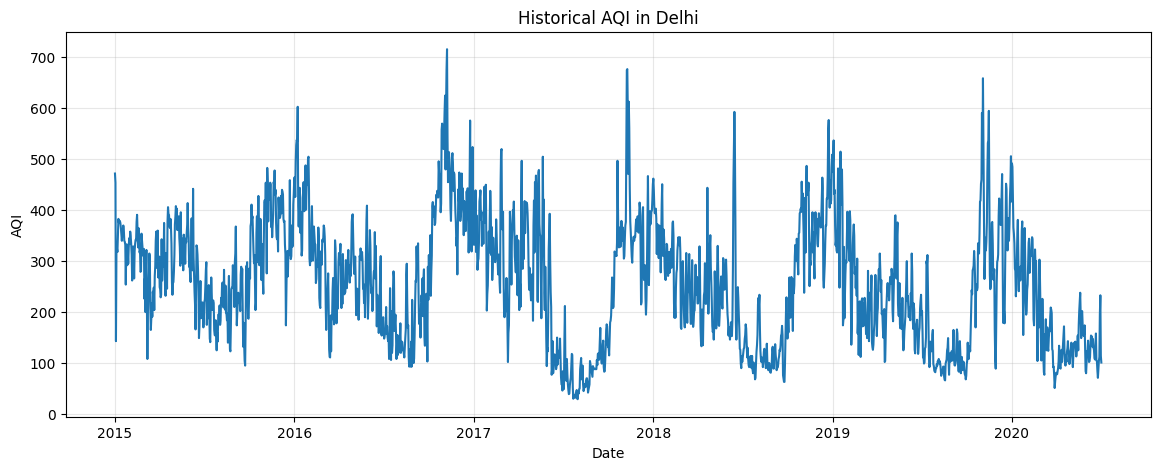

In [6]:
city_name = "Delhi"

city_df = df[df["City"] == city_name][["Date", "AQI"]].copy()

city_df["Date"] = pd.to_datetime(city_df["Date"], errors="coerce")
city_df["AQI"] = pd.to_numeric(city_df["AQI"], errors="coerce")

city_df = (
    city_df.dropna(subset=["Date", "AQI"])
           .groupby("Date", as_index=False)["AQI"].mean()
           .sort_values("Date")
           .reset_index(drop=True)
)

print("Selected city:", city_name)
print("Available AQI records:", len(city_df))
print("Date range:", city_df["Date"].min(), "to", city_df["Date"].max())

plt.figure(figsize=(14, 5))
plt.plot(city_df["Date"], city_df["AQI"])
plt.title(f"Historical AQI in {city_name}")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.grid(True, alpha=0.3)
plt.show()

In [7]:
city_df = city_df.set_index("Date").asfreq("D")

print("Missing AQI values before filling:", city_df["AQI"].isna().sum())

city_df["AQI"] = city_df["AQI"].interpolate(method="time", limit_area="inside")

# Remove any remaining missing values at the beginning or end
city_df = city_df.dropna().reset_index()

print("Daily records after preparation:", len(city_df))
print("Remaining missing values:", city_df["AQI"].isna().sum())

display(city_df.head())

Missing AQI values before filling: 10
Daily records after preparation: 2009
Remaining missing values: 0


,Date,AQI
0,2015-01-01,472.0
1,2015-01-02,454.0
2,2015-01-03,143.0
3,2015-01-04,319.0
4,2015-01-05,325.0


In [8]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Use chronological 80% training and 20% testing
aqi = city_df["AQI"].values.reshape(-1, 1)

split_index = int(len(aqi) * 0.8)

# Fit scaler only on training data
scaler = MinMaxScaler()
scaler.fit(aqi[:split_index])

scaled_aqi = scaler.transform(aqi)

# Use 30 days to predict the next day
LOOKBACK = 30

def create_sequences(data, lookback=30):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

X, y = create_sequences(scaled_aqi, LOOKBACK)

# Sequence target dates determine the chronological split
target_indices = np.arange(LOOKBACK, len(aqi))
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

# LSTM/GRU require [samples, time steps, features]
X_train = X_train.reshape(-1, LOOKBACK, 1)
X_test = X_test.reshape(-1, LOOKBACK, 1)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input shape:", X_train.shape)

Training samples: 1577
Testing samples: 402
Input shape: (1577, 30, 1)


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Last observed AQI in each 30-day input window
baseline_scaled = X_test[:, -1, 0].reshape(-1, 1)

baseline_predictions = scaler.inverse_transform(baseline_scaled).ravel()
actual_aqi = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

baseline_mae = mean_absolute_error(actual_aqi, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(actual_aqi, baseline_predictions))

print(f"Baseline MAE:  {baseline_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")

Baseline MAE:  31.46
Baseline RMSE: 44.97


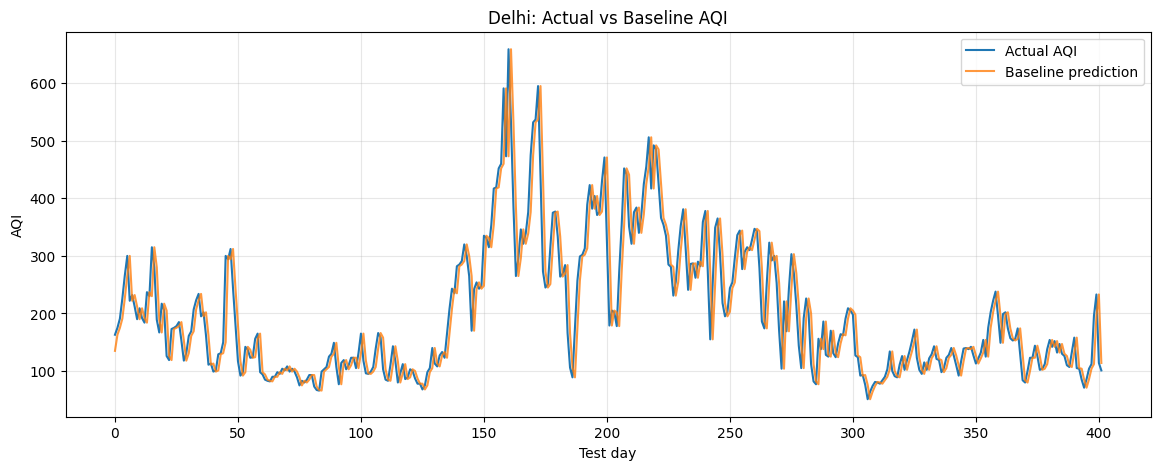

In [10]:
plt.figure(figsize=(14, 5))

plt.plot(actual_aqi, label="Actual AQI")
plt.plot(baseline_predictions, label="Baseline prediction", alpha=0.8)

plt.title(f"{city_name}: Actual vs Baseline AQI")
plt.xlabel("Test day")
plt.ylabel("AQI")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)
np.random.seed(42)

lstm_model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(LOOKBACK, 1)),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - loss: 0.0268 - val_loss: 0.0157
Epoch 2/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0136 - val_loss: 0.0132
Epoch 3/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0129 - val_loss: 0.0124
Epoch 4/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0122 - val_loss: 0.0124
Epoch 5/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0117 - val_loss: 0.0120
Epoch 6/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0113 - val_loss: 0.0118
Epoch 7/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0111 - val_loss: 0.0114
Epoch 8/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0108 - val_loss: 0.0114
Epoch 9/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0106 - val_loss: 0.0111
Epoch 10/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0104 - val_loss: 0.0109
Epoch 11/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0102 - val_loss: 0.0106
Epoch 12/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0097 - val_l

In [12]:
lstm_scaled_predictions = lstm_model.predict(X_test)

lstm_predictions = scaler.inverse_transform(
    lstm_scaled_predictions
).ravel()

lstm_mae = mean_absolute_error(actual_aqi, lstm_predictions)
lstm_rmse = np.sqrt(
    mean_squared_error(actual_aqi, lstm_predictions)
)

print(f"Baseline MAE: {baseline_mae:.2f}")
print(f"LSTM MAE:     {lstm_mae:.2f}")

print(f"\nBaseline RMSE: {baseline_rmse:.2f}")
print(f"LSTM RMSE:     {lstm_rmse:.2f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step
Baseline MAE: 31.46
LSTM MAE:     33.98

Baseline RMSE: 44.97
LSTM RMSE:     45.92


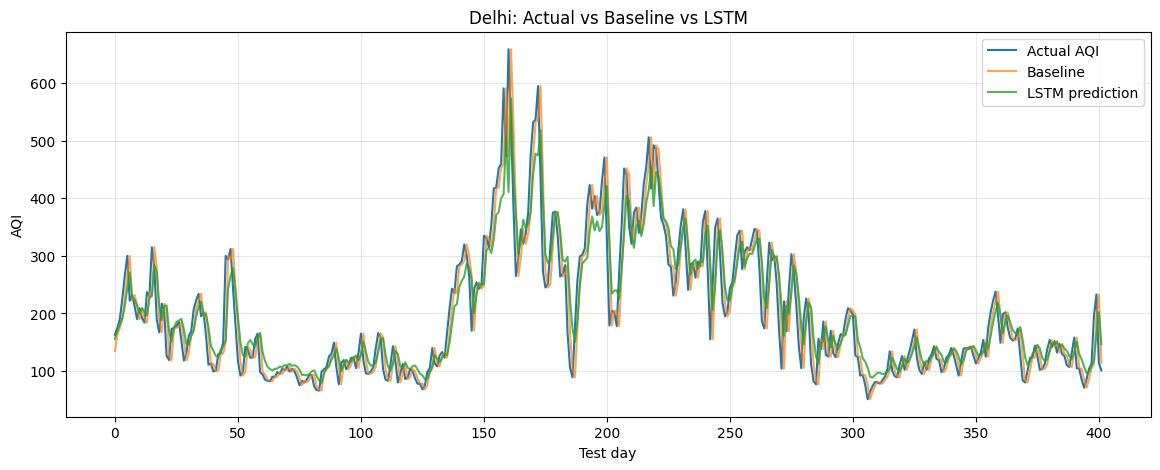

In [13]:
plt.figure(figsize=(14, 5))

plt.plot(actual_aqi, label="Actual AQI")
plt.plot(baseline_predictions, label="Baseline", alpha=0.7)
plt.plot(lstm_predictions, label="LSTM prediction", alpha=0.8)

plt.title(f"{city_name}: Actual vs Baseline vs LSTM")
plt.xlabel("Test day")
plt.ylabel("AQI")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [14]:
from tensorflow.keras.layers import GRU

tf.random.set_seed(42)
np.random.seed(42)

gru_model = Sequential([
    GRU(64, return_sequences=True, input_shape=(LOOKBACK, 1)),
    Dropout(0.2),
    GRU(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

gru_model.compile(
    optimizer="adam",
    loss="mse"
)

gru_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

gru_history = gru_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[gru_early_stop],
    verbose=1
)

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - loss: 0.0231 - val_loss: 0.0111
Epoch 2/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.0115 - val_loss: 0.0098
Epoch 3/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 0.0101 - val_loss: 0.0096
Epoch 4/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0099 - val_loss: 0.0092
Epoch 5/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0090 - val_loss: 0.0088
Epoch 6/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0091 - val_loss: 0.0086
Epoch 7/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0082 - val_loss: 0.0082
Epoch 8/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0082 - val_loss: 0.0080
Epoch 9/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0077 - val_loss: 0.0079
Epoch 10/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.0076 - val_loss: 0.0076
Epoch 11/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.0072 - val_loss: 0.0075
Epoch 12/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0072 - val_l

In [15]:
gru_scaled_predictions = gru_model.predict(X_test)

gru_predictions = scaler.inverse_transform(
    gru_scaled_predictions
).ravel()

gru_mae = mean_absolute_error(actual_aqi, gru_predictions)
gru_rmse = np.sqrt(
    mean_squared_error(actual_aqi, gru_predictions)
)

print(f"GRU MAE:  {gru_mae:.2f}")
print(f"GRU RMSE: {gru_rmse:.2f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step
GRU MAE:  32.23
GRU RMSE: 44.44


In [16]:
results = pd.DataFrame({
    "Model": ["Persistence Baseline", "LSTM", "GRU"],
    "MAE": [baseline_mae, lstm_mae, gru_mae],
    "RMSE": [baseline_rmse, lstm_rmse, gru_rmse]
})

results = results.sort_values("MAE").reset_index(drop=True)
display(results.round(2))

best_model_name = results.iloc[0]["Model"]
print("Lowest-MAE model:", best_model_name)

,Model,MAE,RMSE
0,Persistence Baseline,31.46,44.97
1,GRU,32.23,44.44
2,LSTM,33.98,45.92


Lowest-MAE model: Persistence Baseline


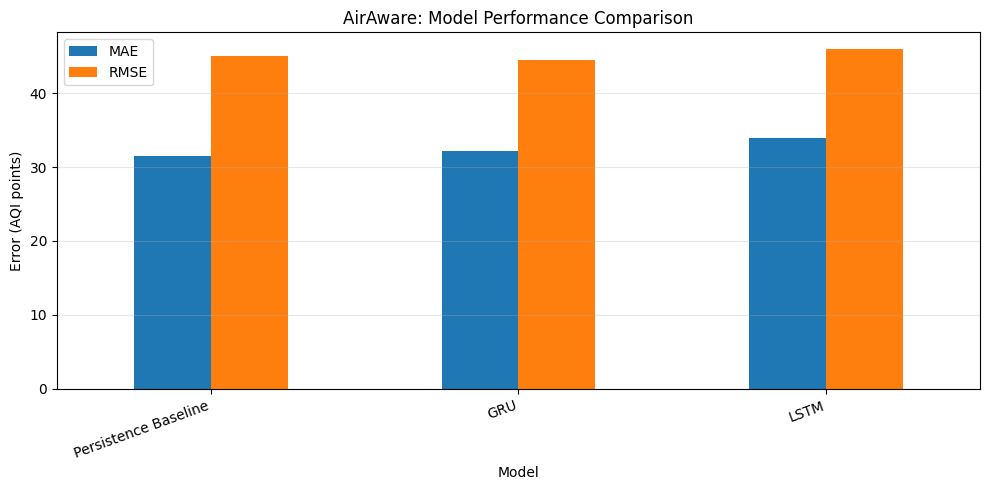

In [17]:
results_plot = results.set_index("Model")[["MAE", "RMSE"]]

results_plot.plot(kind="bar", figsize=(10, 5))
plt.title("AirAware: Model Performance Comparison")
plt.ylabel("Error (AQI points)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
import os
import json
import joblib
from google.colab import files

# Create a folder for deployment files
os.makedirs("airaware_model", exist_ok=True)

# Save trained models
lstm_model.save("airaware_model/lstm_model.keras")
gru_model.save("airaware_model/gru_model.keras")

# Save the scaler
joblib.dump(scaler, "airaware_model/scaler.pkl")

# Save model settings
metadata = {
    "city": city_name,
    "lookback": LOOKBACK,
    "best_model": best_model_name,
    "baseline_mae": float(baseline_mae),
    "baseline_rmse": float(baseline_rmse),
    "lstm_mae": float(lstm_mae),
    "lstm_rmse": float(lstm_rmse),
    "gru_mae": float(gru_mae),
    "gru_rmse": float(gru_rmse)
}

with open("airaware_model/metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Models and metadata saved successfully!")

Models and metadata saved successfully!


In [19]:
import shutil

shutil.make_archive(
    "airaware_model",
    "zip",
    root_dir="airaware_model"
)

files.download("airaware_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
# Check whether the trained models still exist in memory

required_variables = [
    "lstm_model",
    "gru_model",
    "scaler",
    "city_name",
    "LOOKBACK",
    "best_model_name",
    "baseline_mae",
    "baseline_rmse",
    "lstm_mae",
    "lstm_rmse",
    "gru_mae",
    "gru_rmse"
]

for variable in required_variables:
    print(f"{variable}: {'Available' if variable in globals() else 'Missing'}")

lstm_model: Available
gru_model: Available
scaler: Available
city_name: Available
LOOKBACK: Available
best_model_name: Available
baseline_mae: Available
baseline_rmse: Available
lstm_mae: Available
lstm_rmse: Available
gru_mae: Available
gru_rmse: Available


In [21]:
import os
import json
import joblib
import shutil

os.makedirs("/content/airaware_model", exist_ok=True)

# Save trained neural network models
lstm_model.save("/content/airaware_model/lstm_model.keras")
gru_model.save("/content/airaware_model/gru_model.keras")

# Save the preprocessing scaler
joblib.dump(scaler, "/content/airaware_model/scaler.pkl")

# Save the model configuration and evaluation results
metadata = {
    "city": str(city_name),
    "lookback": int(LOOKBACK),
    "best_model": str(best_model_name),
    "baseline_mae": float(baseline_mae),
    "baseline_rmse": float(baseline_rmse),
    "lstm_mae": float(lstm_mae),
    "lstm_rmse": float(lstm_rmse),
    "gru_mae": float(gru_mae),
    "gru_rmse": float(gru_rmse)
}

with open("/content/airaware_model/metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

# Package everything into a ZIP
shutil.make_archive(
    "/content/airaware_model",
    "zip",
    root_dir="/content/airaware_model"
)

print("Saved files:")
print(os.listdir("/content/airaware_model"))
print("\nZIP created at /content/airaware_model.zip")

Saved files:
['scaler.pkl', 'gru_model.keras', 'lstm_model.keras', 'metadata.json']

ZIP created at /content/airaware_model.zip


In [41]:
!ls -la /content/AirAware

total 28
drwxr-xr-x 4 root root 4096 Oct 25 11:15 .
drwxr-xr-x 1 root root 4096 Oct 25 11:16 ..
drwxr-xr-x 2 root root 4096 Oct 25 11:15 airaware_model
-rw-r--r-- 1 root root 2694 Oct 25 11:15 app.py
drwxr-xr-x 8 root root 4096 Oct 25 11:15 .git
-rw-r--r-- 1 root root 1064 Oct 25 11:15 README.md
-rw-r--r-- 1 root root   54 Oct 25 11:15 requirements.txt


In [42]:
!git -C /content/AirAware pull origin main

remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 6.46 KiB | 1.08 MiB/s, done.
From https://github.com/LEOPRITAM01/AirAware-Air_Pollution_Early_Warning
 * branch            main       -> FETCH_HEAD
   dabff54..50e34a5  main       -> origin/main
Updating dabff54..50e34a5
Fast-forward
 app.py | 368 +++++++++++++++++++++++++++++++++++++++++++++++++++++++----------
 1 file changed, 313 insertions(+), 55 deletions(-)


In [43]:
!ls -lh /content/AirAware/airaware_model

total 712K
-rw-r--r-- 1 root root 309K Oct 25 11:15 gru_model.keras
-rw-r--r-- 1 root root 391K Oct 25 11:15 lstm_model.keras
-rw-r--r-- 1 root root  305 Oct 25 11:15 metadata.json
-rw-r--r-- 1 root root  719 Oct 25 11:15 scaler.pkl


In [44]:
%cd /content/AirAware
!pip install -q streamlit joblib pandas numpy scikit-learn tensorflow

/content/AirAware


In [45]:
!streamlit run /content/AirAware/app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.headless true \
  > /content/streamlit.log 2>&1 &

In [46]:
!sleep 5
!tail -40 /content/streamlit.log



2026-10-25 11:28:54.039 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.172.91.67:8501



In [ ]:
!chmod +x /content/cloudflared
! /content/cloudflared tunnel --url http://127.0.0.1:8501

2026-10-25T11:29:23Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-25T11:29:23Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-25T11:29:26Z INF +--------------------------------------------------------------------------------------------+
2026-10-25T11:29:26Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-25T11:29:26Z INF |  https://hunting-suggest-tract-infinite.trycloudflare.